In [ ]:
# notebook to generate coils with preset radius, normal to the magnetic axis, and optimize their currents

from desc.backend import print_backend_info
from desc.coils import (
    CoilSet,
    FourierPlanarCoil,
    MixedCoilSet,
)
import desc.examples
from desc.equilibrium import Equilibrium
from desc.plotting import plot_2d, plot_3d, plot_coils, plot_comparison
from desc.grid import LinearGrid
from desc.optimize import Optimizer
from desc.integrals import compute_B_plasma
import plotly.express as px
import plotly.io as pio
import numpy as np
import pyvista as pv
from desc.dipole import _Dipole, DipoleSet, import_dipoles
from desc.io import load
import matplotlib.pyplot as plt
import jax.numpy as jnp
from desc.grid import LinearGrid
from scipy.optimize import minimize
import plotly.express as px
import plotly.io as pio
pio.renderers.default = "plotly_mimetype+notebook"
print_backend_info()

plot_grid = LinearGrid(M=20, N=40, NFP=1, endpoint=True)

eq = load('eq_final (8).h5')
coilset_r = load('coilset_stage_two_qf_final.h5')

DESC version=0.16.0+118.g5ea8912bd.dirty.
Using JAX backend: jax version=0.7.2, jaxlib version=0.7.2, dtype=float64.
Using device: CPU, with 3.49 GB available memory.


In [18]:

offset = 0.1
target_size = .305
B_desired = .15
from desc.compat import rescale
eq_new = rescale(eq, L = ('R0',target_size),B = ('B0',B_desired) )
minor_radius = eq_new.compute("a")["a"]
R0_before = eq_new.compute('R0')['R0']
scale = target_size / R0_before
num_coils = 6  # coils per half field period
zeta = np.linspace(0, np.pi / eq.NFP, num_coils, endpoint=False) + np.pi / (2 * eq.NFP * num_coils)
grid = LinearGrid(rho=[0.0], M=0, zeta=zeta, NFP=eq.NFP)
data = eq.axis.compute(["x", "x_s"], grid=grid, basis="rpz")
centers = data["x"]  # center coils on axis position
normals = data["x_s"]  # make normal to coil align with tangent along axis
unique_coils = []
for k in range(num_coils):
    coil = FourierPlanarCoil(
        current=10000,
        #current=50000,
        center=centers[k, :],
        normal=normals[k, :],
        r_n=0.105,
        basis="rpz",
    )
    #.to_FourierXYZ(N=4) 
    unique_coils.append(coil)
coilset = CoilSet(unique_coils, NFP=eq.NFP, sym=eq.sym)



for c in coilset:
    c.center = c.center * scale
    c.current = c.current * (target_size / R0_before)

coil_grid = LinearGrid(N=40)

fig = plot_3d(
    eq_new.surface, "B*n", field=coilset, field_grid=coil_grid, grid=plot_grid
)

fig = plot_coils(coilset, fig=fig)
fig.show()

In [20]:
from desc.compat import rescale
import numpy as np
coilset_r = load('coilset_stage_two_qf_final.h5')
# Target MUSE parameters
target_size = 0.305
B_desired = 0.15
coil_radius = 0.105
num_coils = 6

R0_original = float(eq.compute("R0")["R0"])
axis_data_original = eq.compute(
    ["|B|"],
    grid=LinearGrid(
        rho=0.0,
        theta=0.0,
        N=1,
        NFP=eq.NFP,
    ),
)

B0_original = float(np.asarray(axis_data_original["|B|"]).ravel()[0])

# Rescale the equilibrium
eq_new = rescale(
    eq,
    L=("R0", target_size),
    B=("B0", B_desired),
)

# Generate coil centers and normals on the RESCALED magnetic axis
zeta = (
    np.linspace(0, np.pi / eq_new.NFP, num_coils, endpoint=False)
    + np.pi / (2 * eq_new.NFP * num_coils)
)

grid = LinearGrid(
    rho=[0.0],
    M=0,
    zeta=zeta,
    NFP=eq_new.NFP,
)

data = eq_new.axis.compute(
    ["x", "x_s"],
    grid=grid,
    basis="rpz",
)

centers = np.asarray(data["x"])
normals = np.asarray(data["x_s"])

# Initial currents from the loaded coilset
I_seed = np.asarray(coilset_r.current).ravel()

print("Number of loaded currents:", len(I_seed))
print("Number of requested coils:", num_coils)

unique_coils = []

for k in range(num_coils):
    coil = FourierPlanarCoil(current=I_seed[k],center=centers[k],normal=normals[k],r_n=coil_radius,basis="rpz",)
    unique_coils.append(coil)

coilset = CoilSet(
    unique_coils,
    NFP=eq_new.NFP,
    sym=eq_new.sym,
)

I_seed = (
    np.asarray(coilset_r.current).ravel()
    * (target_size / R0_original)
    * (B_desired / B0_original)
)

Number of loaded currents: 8
Number of requested coils: 6


In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from desc.grid import LinearGrid

# --------------------------------------------------
# 1. Evaluate equilibrium |B| on the rescaled axis
# --------------------------------------------------
N_axis = 100

axis_grid = LinearGrid(
    rho=0.0,
    theta=0.0,
    N=N_axis,
    NFP=eq_new.NFP,
    endpoint=True,
)

axis_data = eq_new.compute(
    ["|B|", "X", "Y", "Z"],
    grid=axis_grid,
)

axis_pts = np.column_stack([
    np.asarray(axis_data["X"]).ravel(),
    np.asarray(axis_data["Y"]).ravel(),
    np.asarray(axis_data["Z"]).ravel(),
])

B_eq = np.asarray(axis_data["|B|"]).ravel()

# --------------------------------------------------
# 2. Save initial currents
# --------------------------------------------------
I0 = np.array([float(c.current) for c in unique_coils])

print("Number of coils:", len(unique_coils))
print("Initial currents [A]:", I0)

# --------------------------------------------------
# 3. Define residual: coil |B| - equilibrium |B|
# --------------------------------------------------
def residual(I):
    # Update currents only; geometry is unchanged
    for c, current in zip(unique_coils, I):
        c.current = current

    B_vec = coilset.compute_magnetic_field(
        axis_pts,
        basis="xyz",
    )

    B_coils = np.linalg.norm(np.asarray(B_vec), axis=-1)

    return B_coils - B_eq

# --------------------------------------------------
# 4. Optimize
# --------------------------------------------------
rms_initial = np.sqrt(np.mean(residual(I0)**2))

result = least_squares(
    residual,
    I0,
    method="trf",
    x_scale="jac",
    max_nfev=2000,
    verbose=1,
)

I_opt = result.x

# Set coils to optimized currents
for c, current in zip(unique_coils, I_opt):
    c.current = current

r_final = residual(I_opt)
rms_final = np.sqrt(np.mean(r_final**2))

print("\nOptimization success:", result.success)
print("Message:", result.message)
print(f"Initial RMS error: {rms_initial:.6e} T")
print(f"Final RMS error:   {rms_final:.6e} T")
print("Optimized currents [A]:", I_opt)

# --------------------------------------------------
# 5. Plot comparison
# --------------------------------------------------
B_coils_opt = np.linalg.norm(
    np.asarray(
        coilset.compute_magnetic_field(axis_pts, basis="xyz")
    ),
    axis=-1,
)

Number of coils: 6
Initial currents [A]: [736843.7809463  716340.19394496 697667.27966463 712724.80527842
 706840.75948696 637877.25924198]
`gtol` termination condition is satisfied.
Function evaluations 3, initial cost 2.4061e+04, final cost 6.3543e-06, first-order optimality 4.03e-10.

Optimization success: True
Message: `gtol` termination condition is satisfied.
Initial RMS error: 1.547291e+01 T
Final RMS error:   2.514500e-04 T
Optimized currents [A]: [ 9087.82282997  8809.62950182 11732.99211076  4650.32479193
  3508.41441838  2030.04932215]


In [23]:
coilset.save('qipm_coils.h5', file_format=None, file_mode='w')

In [20]:
eq_new.save('qipm2.h5', file_format=None, file_mode='w')

/Users/jessicali/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 3.

/Users/jessicali/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 3.



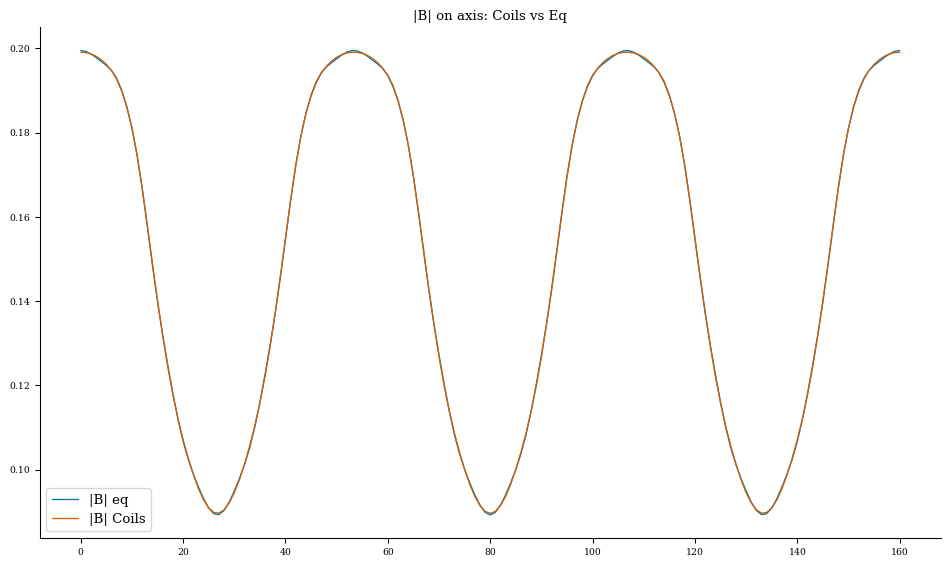

In [22]:
plot_grid = LinearGrid(M=20, N=40, NFP=1, endpoint=True)
axis_grid = LinearGrid(rho=0, theta = 0, N=80, NFP=1, endpoint=True)
fig, ax = plt.subplots(1,1, figsize = (10,6))
data_axis_eq = eq_new.compute(['|B|','X','Y','Z'], grid = axis_grid)

axis_pts = np.array([data_axis_eq["X"],data_axis_eq["Y"],data_axis_eq["Z"]]).T

ax.plot(data_axis_eq['|B|'], label='|B| eq')
ax.set_title('|B| on axis: Coils vs Eq')

modB_on_axis_coils = np.linalg.norm(coilset.compute_magnetic_field(axis_pts, basis='xyz'), axis = -1)
ax.plot(modB_on_axis_coils,label='|B| Coils')

ax.legend()